In [157]:
import numpy as np
from fixed_T_simulation import return_vals
from matplotlib import pyplot as plt

In [185]:
T_vals, sum_exp_vals = return_vals('IXXIII', n=6)
len(T_vals), len(sum_exp_vals)

(199, 199)

In [191]:
T_vals_20 = T_vals[:40]
sum_exp_vals_20 = sum_exp_vals[:40]
len(sum_exp_vals_20), len(T_vals_20)

(40, 40)

In [209]:
diff = []
for i in range(len(T_vals_20) - 1):
    diff.append(sum_exp_vals_20[i+1] - sum_exp_vals_20[i])
len(diff)

39

In [217]:
diff_2nd = []
for i in range(len(T_vals_20) - 2):
    diff_2nd.append(diff[i+1] - diff[i])
len(diff_2nd)

38

In [215]:
diff_avg = []
for i in range(len(T_vals_20) - 2):
    diff_avg.append((diff[i] + diff[i+1])/2)
len(diff_avg)

38

In [221]:
smallest_idx_2nd = 0
smallest_num_2nd = diff_avg[0]
for i in range(len(T_vals_20) - 2):
    if diff_2nd[i] < smallest_num_2nd:
        smallest_idx_2nd = i
        smallest_num_2nd = diff_2nd[i]
smallest_idx_2nd, smallest_num_2nd

(36, -0.0016021731133923165)

In [43]:
smallest_idx = 0
smallest_num = diff_avg[0]
for i in range(len(T_vals_20)):
    if diff_avg[i] < smallest_num:
        smallest_idx = i
        smallest_num = diff_avg[i]
smallest_idx, smallest_num

(9, 6.487799110989389e-05)

In [225]:
def calc_stable_pt(T_vals, sum_exp_vals):
    section = [0, 40, 80, 120, 160, 199]
    smallest_idxs = []
    smallest_nums = []
    for i in range(len(section)-1):
        section_begin = section[i]
        section_end = section[i+1]

        # print('section_begin: ')
        # print(section_begin)
        # print('section_end: ')
        # print(section_end)
        
        T_vals_section = T_vals[section_begin:section_end]
        sum_exp_section = sum_exp_vals[section_begin:section_end]

        diff = [0]
        for i in range(len(T_vals_section) - 1):
            diff.append(sum_exp_section[i+1] - sum_exp_section[i])
        diff.append(0)

        diff_avg = []
        for i in range(len(T_vals_section)):
            diff_avg.append((diff[i] + diff[i+1])/2)

        smallest_idx = 0
        smallest_num = abs(diff_avg[0])
        for i in range(len(T_vals_section)):
            if abs(diff_avg[i]) < smallest_num:
                smallest_idx = i
                smallest_num = abs(diff_avg[i])

        smallest_idxs.append(smallest_idx+section_begin)
        smallest_nums.append(smallest_num)
        # print(smallest_idx)
        # print(smallest_num)

    return smallest_idxs, smallest_nums

In [235]:
def calc_stable_pt_2nd(T_vals, sum_exp_vals):
    section = [0, 40, 80, 120, 160, 199]
    smallest_idxs = []
    smallest_nums = []
    for i in range(len(section)-1):
        section_begin = section[i]
        section_end = section[i+1]

        # print('section_begin: ')
        # print(section_begin)
        # print('section_end: ')
        # print(section_end)
        
        T_vals_section = T_vals[section_begin:section_end]
        sum_exp_section = sum_exp_vals[section_begin:section_end]

        diff = []
        for i in range(len(T_vals_section) - 1):
            diff.append(sum_exp_section[i+1] - sum_exp_section[i])

        diff_2nd = []
        for i in range(len(T_vals_section) - 2):
            diff_2nd.append(diff[i+1] - diff[i])

        smallest_idx = 0
        smallest_num = abs(diff_avg[0])
        for i in range(len(diff_2nd)):
            if abs(diff_avg[i]) < smallest_num:
                smallest_idx = i
                smallest_num = abs(diff_avg[i])

        smallest_idxs.append(smallest_idx+section_begin+1)
        smallest_nums.append(smallest_num)
        # print(smallest_idx)
        # print(smallest_num)

    return smallest_idxs, smallest_nums

In [153]:
# no abs
smallest_idxs, smallest_nums = calc_stable_pt(T_vals, sum_exp_vals)
smallest_idxs, smallest_nums

([9, 60, 114, 123, 197],
 [6.487799110989389e-05,
  6.641686686664414e-05,
  -0.0003005988807377631,
  -0.0011446516386580258,
  -0.0006304820692061425])

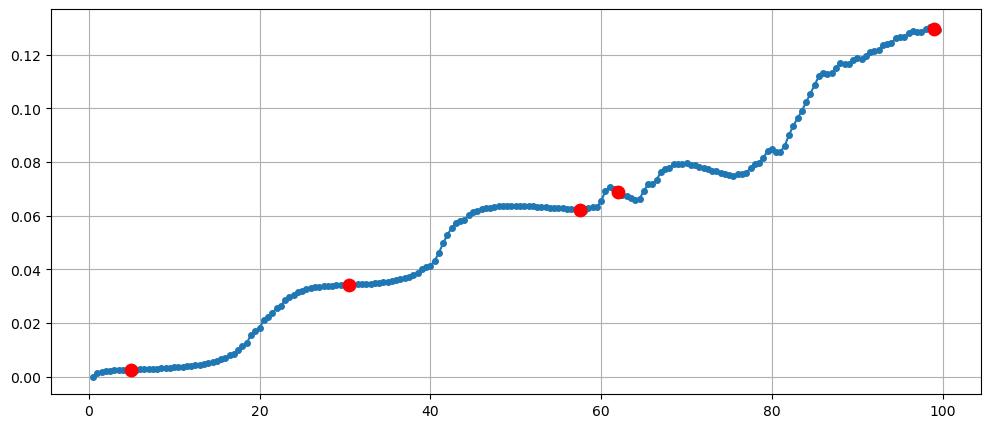

In [169]:
plt.figure(figsize=(12, 5))
plt.plot(T_vals, sum_exp_vals, "o-", markersize=4, label=f"observable={'IXXIII'}")
plt.grid(True)
plt.scatter(
    np.array(T_vals)[smallest_idxs],
    np.array(sum_exp_vals)[smallest_idxs],
    color="red",
    s=80,
    zorder=5,
    label="selected indices"
)
plt.show()

In [173]:
smallest_idxs_abs, smallest_nums_abs = calc_stable_pt(T_vals, sum_exp_vals)
smallest_idxs_abs, smallest_nums_abs

([9, 60, 98, 150, 160],
 [6.487799110989389e-05,
  6.641686686664414e-05,
  1.121544105046196e-05,
  3.081941037366698e-05,
  6.352491137791294e-06])

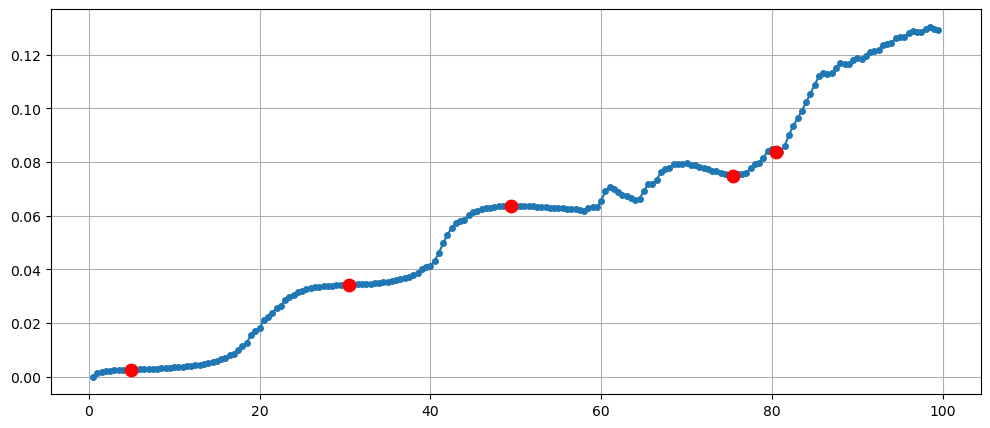

In [175]:
plt.figure(figsize=(12, 5))
plt.plot(T_vals, sum_exp_vals, "o-", markersize=4, label=f"observable={'IXXIII'}")
plt.grid(True)
plt.scatter(
    np.array(T_vals)[smallest_idxs_abs],
    np.array(sum_exp_vals)[smallest_idxs_abs],
    color="red",
    s=80,
    zorder=5,
    label="selected indices"
)
plt.show()

In [ ]:
def calc_stable_pt(T_vals, sum_exp_vals):
    section = [0, 40, 80, 120, 160, 199]
    smallest_idxs = []
    smallest_nums = []
    for i in range(len(section)-1):
        section_begin = section[i]
        section_end = section[i+1]

        # print('section_begin: ')
        # print(section_begin)
        # print('section_end: ')
        # print(section_end)
        
        T_vals_section = T_vals[section_begin:section_end]
        sum_exp_section = sum_exp_vals[section_begin:section_end]

        diff = [0]
        for i in range(len(T_vals_section) - 1):
            diff.append(sum_exp_section[i+1] - sum_exp_section[i])
        diff.append(0)

        diff_avg = []
        for i in range(len(T_vals_section)):
            diff_avg.append((diff[i] + diff[i+1])/2)

        diff_avg_second = []
        for i in range(len(T_vals_section)):
            diff_avg.append((diff[i] + diff[i+1])/2)

        smallest_idx = 0
        smallest_num = abs(diff_avg[0])
        for i in range(len(T_vals_section)):
            if abs(diff_avg[i]) < smallest_num:
                smallest_idx = i
                smallest_num = abs(diff_avg[i])

        smallest_idxs.append(smallest_idx+section_begin)
        smallest_nums.append(smallest_num)
        # print(smallest_idx)
        # print(smallest_num)

    return smallest_idxs, smallest_nums

In [237]:
# diff_2nd
smallest_idxs, smallest_nums = calc_stable_pt_2nd(T_vals, sum_exp_vals)
smallest_idxs, smallest_nums

([9, 49, 89, 129, 169],
 [6.487799110989389e-05,
  6.487799110989389e-05,
  6.487799110989389e-05,
  6.487799110989389e-05,
  6.487799110989389e-05])

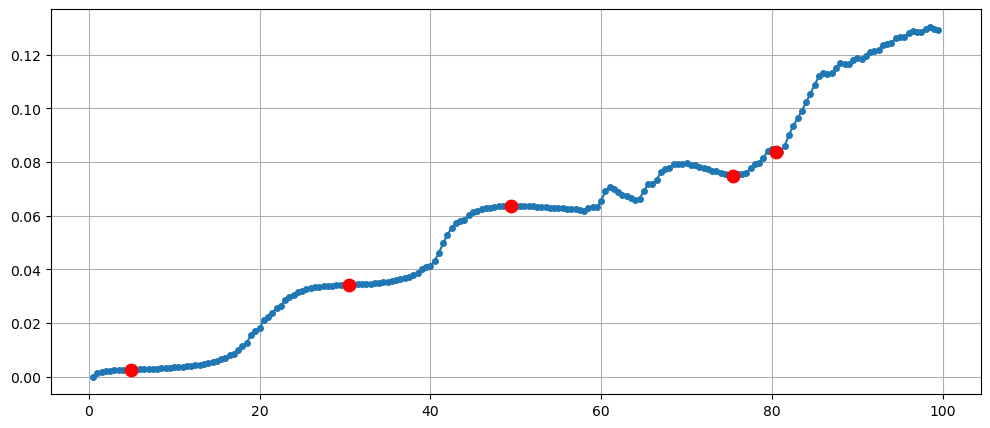

In [239]:
plt.figure(figsize=(12, 5))
plt.plot(T_vals, sum_exp_vals, "o-", markersize=4, label=f"observable={'IXXIII'}")
plt.grid(True)
plt.scatter(
    np.array(T_vals)[smallest_idxs_abs],
    np.array(sum_exp_vals)[smallest_idxs_abs],
    color="red",
    s=80,
    zorder=5,
    label="selected indices"
)
plt.show()